#Project 1: Fossil Fuel Consumption Data Analysis

##Overview

Analysis of Indonesia’s annual fossil fuel supply (or, consumption) by type (gas, oil, and coal) and the CO2 produced from the fossil fuel consumption (also by type).

##Analysis

In [34]:
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

#Fossil fuel supply
urllib.request.urlretrieve("https://raw.githubusercontent.com/JojoJojo12345/Data-Analysis-with-Python-Course/refs/heads/main/project1/pandas_fossil-fuel-supply-by-source.csv", "fossil.csv")
fossil_df = pd.read_csv("fossil.csv")
fossil_df = fossil_df[fossil_df["Entity"] == "Indonesia"]
fossil_df.columns = list(fossil_df.columns[0:3]) + ["Gas supply", "Oil supply", "Coal supply"]
fossil_df["Annual fossil fuel supply"] = fossil_df["Gas supply"] + fossil_df["Oil supply"] + fossil_df["Coal supply"]
fossil_df["Gas supply to fuel supply ratio"] = fossil_df["Gas supply"] / fossil_df["Annual fossil fuel supply"]
fossil_df["Oil supply to fuel supply ratio"] = fossil_df["Oil supply"] / fossil_df["Annual fossil fuel supply"]
fossil_df["Coal supply to fuel supply ratio"] = fossil_df["Coal supply"] / fossil_df["Annual fossil fuel supply"]

#CO2 emissions from fossil fuel supply BY TYPE
urllib.request.urlretrieve("https://raw.githubusercontent.com/JojoJojo12345/Data-Analysis-with-Python-Course/refs/heads/main/project1/pandas_annual-co2-emissions-by-source.csv", "co2_by_source.csv")
co2_by_source_df = pd.read_csv("co2_by_source.csv")
co2_by_source_df.drop(columns = ["Other industry", "Flaring", "Cement"], inplace = True)
co2_by_source_df.columns = list(co2_by_source_df.columns[0:3]) + ["CO2 from gas", "CO2 from oil", "CO2 from coal"]
co2_by_source_df["Annual CO2 emissions from fossil fuel"] = co2_by_source_df["CO2 from gas"] + co2_by_source_df["CO2 from oil"] + co2_by_source_df["CO2 from coal"]

#Fossil fuel supply & CO2 emissions
df = fossil_df.merge(co2_by_source_df, on = ["Entity", "Code", "Year"])
df.set_index(df["Year"], inplace = True)
df["CO2 from gas to gas supply ratio"] = df["CO2 from gas"] / df["Gas supply"]
df["CO2 from oil to oil supply ratio"] = df["CO2 from oil"] / df["Oil supply"]
df["CO2 from coal to coal supply ratio"] = df["CO2 from coal"] / df["Coal supply"]
df["CO2 emissions to fossil fuel supply ratio"] = df["Annual CO2 emissions from fossil fuel"] / df["Annual fossil fuel supply"]

In [35]:
df

,Entity,Code,Year,Gas supply,Oil supply,Coal supply,Annual fossil fuel supply,Gas supply to fuel supply ratio,Oil supply to fuel supply ratio,Coal supply to fuel supply ratio,CO2 from gas,CO2 from oil,CO2 from coal,Annual CO2 emissions from fossil fuel,CO2 from gas to gas supply ratio,CO2 from oil to oil supply ratio,CO2 from coal to coal supply ratio,CO2 emissions to fossil fuel supply ratio
Year,,,,,,,,,,,,,,,,,,
1965,Indonesia,IDN,1965,5.075000,72.543625,1.500270,79.118895,0.064144,0.916894,0.018962,6056592,17667808,762112.0,24486512.0,1.193417e+06,243547.355126,507983.229685,309490.064379
1966,Indonesia,IDN,1966,5.176500,69.864460,1.837540,76.878500,0.067334,0.908765,0.023902,6071248,16238848,897680.0,23207776.0,1.172848e+06,232433.600718,488522.698826,301876.025157
1967,Indonesia,IDN,1967,6.323450,67.402800,1.290930,75.017180,0.084293,0.898498,0.017208,6122544,17623840,619216.0,24365600.0,9.682284e+05,261470.443364,479666.596949,324800.265752
1968,Indonesia,IDN,1968,6.424950,71.299310,0.965290,78.689550,0.081649,0.906084,0.012267,6309408,20577024,472656.0,27359088.0,9.820167e+05,288600.604971,489651.839844,347683.879465
1969,Indonesia,IDN,1969,12.108950,76.334076,1.163000,89.606026,0.135135,0.851886,0.012979,4998245,27537984,560654.0,33096883.0,4.127728e+05,360756.105831,482075.624929,369360.013389
1970,Indonesia,IDN,1970,12.575850,80.992670,1.011810,94.580331,0.132965,0.856337,0.010698,2300992,29213072,432352.0,31946416.0,1.829691e+05,360687.849900,427305.521788,337770.187851
1971,Indonesia,IDN,1971,12.717950,83.943830,1.163000,97.824780,0.130007,0.858104,0.011889,2711360,31576352,553264.0,34840976.0,2.131916e+05,376160.487316,475721.369241,356156.957004
1972,Indonesia,IDN,1972,12.474350,90.783680,1.163000,104.421030,0.119462,0.869400,0.011138,1996880,34562510,523952.0,37083342.0,1.600789e+05,380712.810937,450517.588090,355132.888121
1973,Indonesia,IDN,1973,8.120000,108.374560,0.779210,117.273770,0.069240,0.924116,0.006644,3143712,38713824,355408.0,42212944.0,3.871567e+05,357222.433014,456113.242900,359952.135929


###General trends

Text(0, 0.5, 'Fossil fuel supply (in TWh)')

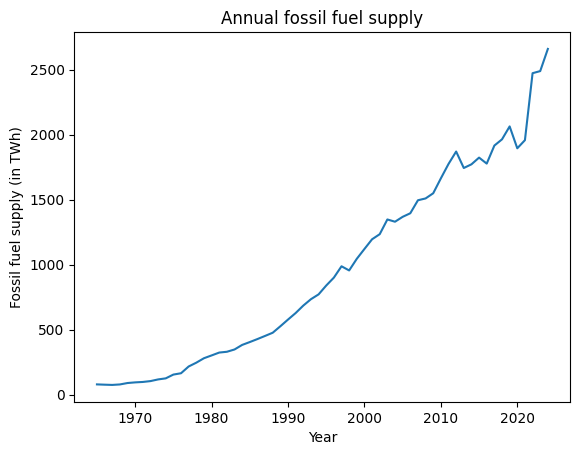

In [36]:
plt.plot("Year", "Annual fossil fuel supply", data = df)
plt.title("Annual fossil fuel supply")
plt.xlabel("Year")
plt.ylabel("Fossil fuel supply (in TWh)")

Text(0, 0.5, 'CO2 emissions (in tonnes)')

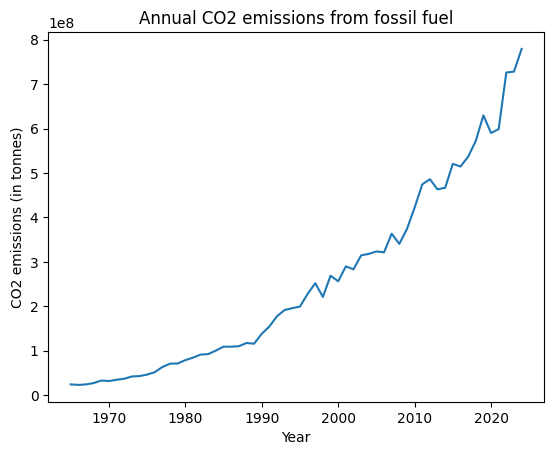

In [37]:
plt.plot("Year", "Annual CO2 emissions from fossil fuel", data = df)
plt.title("Annual CO2 emissions from fossil fuel")
plt.xlabel("Year")
plt.ylabel("CO2 emissions (in tonnes)")

Text(0, 0.5, 'CO2 emissions to fossil fuel supply ratio (tonnes/TWh)')

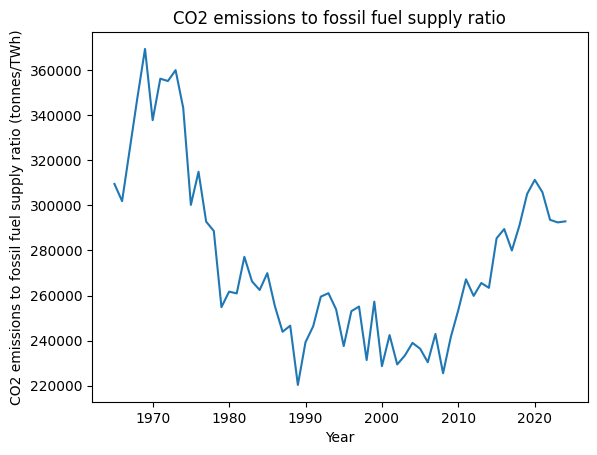

In [38]:
plt.plot("Year", "CO2 emissions to fossil fuel supply ratio", data = df)
plt.title("CO2 emissions to fossil fuel supply ratio")
plt.xlabel("Year")
plt.ylabel("CO2 emissions to fossil fuel supply ratio (tonnes/TWh)")

Analysis:
1. Annual fuel supply shows an growing trend, with a rapid rise in the 2020s.
2. Fuel supply rise is accompanied by an increase in CO2 emissions.
3. In the mid 1970s, there was a sharp decline in CO2 emissions to fuel supply ratio. However, since the 2010s, the number started to grow significantly, showing that CO2 emissions from fuel supply were more efficient in between these two periods.

###By fuel type

Text(0, 0.5, 'Fossil fuel supply (TWh)')

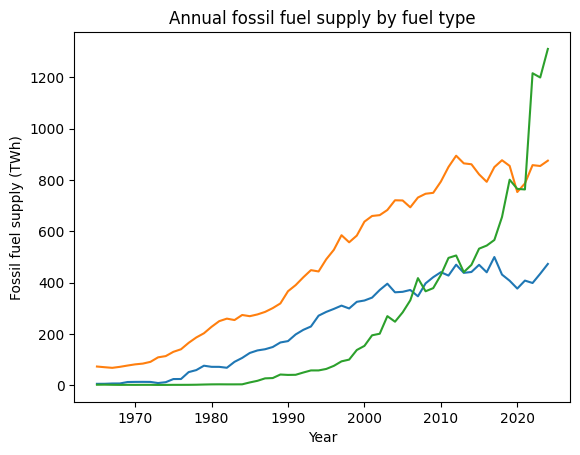

In [39]:
plt.plot("Year", "Gas supply", data = df)
plt.plot("Year", "Oil supply", data = df)
plt.plot("Year", "Coal supply", data = df)
plt.title("Annual fossil fuel supply by fuel type")
plt.xlabel("Year")
plt.ylabel("Fossil fuel supply (TWh)")

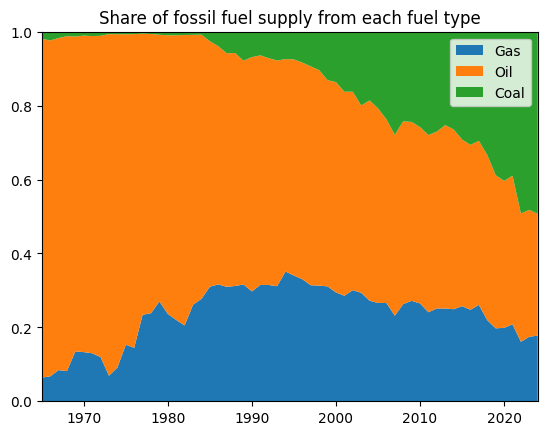

In [40]:
plt.title("Share of fossil fuel supply from each fuel type")
plt.margins(0, 0)
plt.stackplot(df["Year"], df["Gas supply to fuel supply ratio"], df["Oil supply to fuel supply ratio"], df["Coal supply to fuel supply ratio"])
plt.legend(["Gas", "Oil", "Coal"])

Text(0, 0.5, 'CO2 emissions per fuel supply (tonnes/TWh)')

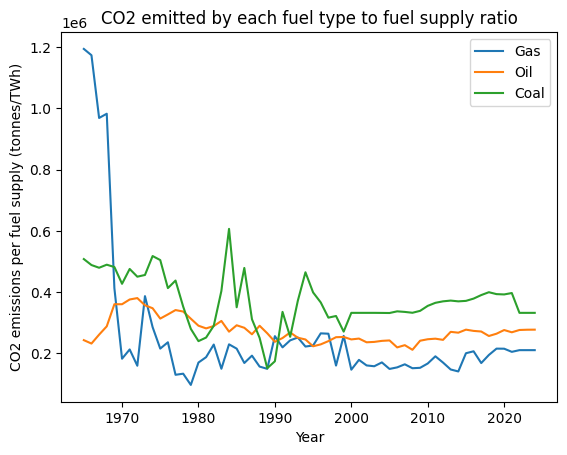

In [41]:
plt.title("CO2 emitted by each fuel type to fuel supply ratio")
plt.plot("Year", "CO2 from gas to gas supply ratio", data = df)
plt.plot("Year", "CO2 from oil to oil supply ratio", data = df)
plt.plot("Year", "CO2 from coal to coal supply ratio", data = df)
plt.legend(["Gas", "Oil", "Coal"])
plt.xlabel("Year")
plt.ylabel("CO2 emissions per fuel supply (tonnes/TWh)")

Analysis:
1. Since 1965, the proportion of oil supply has been decreasing, while coal supply has been growing significantly, especially in 1990 to 2024.
2. Before 1970, the ratio of CO2 emissions to gas supply was extremely large, but it rapidly drops to around 100,000 to 400,000 tonnes/TWh, making it the lowest, in overall.
3. In general, coal contributes the most to CO2 emissions from fossil fuel.

##Resources
**Energy Institute – Statistical Review of World Energy (2026); Smil (2017) – with major processing by Our World in Data**

Total energy supply is a measure of primary energy: **the energy available to a country or region before it is converted into electricity or fuels for final use**. It counts **energy produced domestically or imported, minus what is exported or stored**.
Each source is measured by its physical energy content: fossil fuels and biomass by the heat released when they are burned; nuclear and geothermal by the heat they produce; and wind, solar, and hydropower by the electricity they generate.

OWID: https://ourworldindata.org/grapher/energy-mix?time=earliest..2024&country=~IDN&metric=by_source&source=fossil_fuels

GitHub: https://raw.githubusercontent.com/JojoJojo12345/Data-Analysis-with-Python-Course/refs/heads/main/project1/pandas_fossil-fuel-supply-by-source.csv

Unit of measurement: TWh


---


**Global Carbon Budget (2025) – with major processing by Our World in Data**

OWID: https://ourworldindata.org/grapher/co2-by-source?time=1965..latest&country=~IDN&tableFilter=all&tableSearch=indones&v=1&csvType=filtered&useColumnShortNames=false

GitHub: https://raw.githubusercontent.com/JojoJojo12345/Data-Analysis-with-Python-Course/refs/heads/main/project1/pandas_annual-co2-emissions-by-source.csv

Unit of measurement: tonne